In [1]:

import numpy as np
import pandas as pd

from lifelines import CoxPHFitter
from lifelines import KaplanMeierFitter
from lifelines import AalenJohansenFitter  # for cumulative incidence (competing risks) :contentReference[oaicite:1]{index=1}

# from sksurv.util import Surv  
# from sksurv.ensemble import RandomSurvivalForest 
# from sksurv.metrics import concordance_index_censored

In [2]:
import os
import re
import numpy as np
import pandas as pd

pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 200)

# Paths:
DATA_DIR = os.path.join('..', 'data')
OUT_DIR  = os.path.join('..', 'output')
os.makedirs(OUT_DIR, exist_ok=True)

NACC_MAIN_PATH = os.path.join(DATA_DIR, 'investigator_nacc72.csv')

USE_ONLY_V3 = False   # True => keep only FORMVER in {3, 3.2}

# Horizon sweep range
MIN_H = 3
MAX_H = 12

In [3]:
df = pd.read_csv(NACC_MAIN_PATH, low_memory=False)
df['NACCID'] = df['NACCID'].astype(str)

def make_visit_date(df_: pd.DataFrame) -> pd.Series:
    y = pd.to_numeric(df_['VISITYR'], errors='coerce')
    m = pd.to_numeric(df_['VISITMO'], errors='coerce').fillna(6).astype(int).clip(1, 12)
    d = pd.to_numeric(df_['VISITDAY'], errors='coerce').fillna(15).astype(int).clip(1, 28)
    return pd.to_datetime(dict(year=y, month=m, day=d), errors='coerce')

df['visit_date'] = make_visit_date(df)
df = df.dropna(subset=['NACCID', 'visit_date']).copy()
df = df.sort_values(['NACCID', 'visit_date']).reset_index(drop=True)

if 'FORMVER' in df.columns:
    df['FORMVER'] = pd.to_numeric(df['FORMVER'], errors='coerce')

print('Rows:', len(df), 'Participants:', df['NACCID'].nunique())
df[['NACCID','visit_date'] + ([ 'FORMVER' ] if 'FORMVER' in df.columns else [])].head()

Rows: 207454 Participants: 55268


,NACCID,visit_date,FORMVER
0,NACC000011,2006-04-17,1.0
1,NACC000011,2007-06-18,1.0
2,NACC000011,2008-06-03,2.0
3,NACC000011,2009-08-03,2.0
4,NACC000034,2015-07-16,3.0


In [4]:


if "DEMENTED" in df.columns:
    no_dem_mask = df["DEMENTED"] == 0
else:
    no_dem_mask = pd.Series(True, index=df.index)

if "NACCUDSD" in df.columns:
    cnmci_mask = df["NACCUDSD"].isin([1,2,3])
else:
    cn_mask = (df["NORMCOG"] == 1) if "NORMCOG" in df.columns else pd.Series(False, index=df.index)
    mci_mask = df["NACCTMCI"].isin([1,2,3,4]) if "NACCTMCI" in df.columns else pd.Series(False, index=df.index)

    if ("NORMCOG" in df.columns) or ("NACCTMCI" in df.columns):
        cnmci_mask = cn_mask | mci_mask
    else:
        cnmci_mask = pd.Series(True, index=df.index)

eligible = df[no_dem_mask & cnmci_mask].copy()

baseline = (
    eligible
    .sort_values(["NACCID","visit_date"])
    .groupby("NACCID", as_index=False)
    .first()
)

baseline = baseline[["NACCID","visit_date"]]
baseline = baseline.rename(columns={"visit_date":"baseline_date"})

print("Baseline participants:", len(baseline))
baseline.head()

C:\Users\branjan\AppData\Local\Temp\ipykernel_24320\2428668717.py:23: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .first()


Baseline participants: 38341


,NACCID,baseline_date
0,NACC000011,2006-04-17
1,NACC000034,2015-07-16
2,NACC000067,2012-05-23
3,NACC000073,2016-05-20
4,NACC000138,2023-07-13


In [5]:
def years_between(a: pd.Series, b: pd.Series) -> pd.Series:
    return (b - a).dt.days / 365.25

keep_ids = set(baseline['NACCID'])
df2 = df[df['NACCID'].isin(keep_ids)].merge(
    baseline[['NACCID','baseline_date']], on='NACCID', how='left'
).copy()

df2['t_years'] = years_between(df2['baseline_date'], df2['visit_date'])
post = df2[df2['t_years'] > 0].copy()

print("=== CHECKPOINT: post ===")
print("baseline N:", baseline["NACCID"].nunique())
print("post rows:", len(post), " post unique IDs:", post["NACCID"].nunique())
print("post visit_date min/max:", post["visit_date"].min(), post["visit_date"].max())
print("t_years min/max:", post["t_years"].min(), post["t_years"].max())

max_follow = post.groupby('NACCID')['t_years'].max().rename('max_follow_years')
baseline2 = baseline.merge(max_follow, on='NACCID', how='left')

print("\n=== CHECKPOINT: follow-up ===")
print("max_follow_years describe:")
display(baseline2["max_follow_years"].describe())
print("eligible @4y:", (baseline2["max_follow_years"] >= 4).sum())
print("eligible @5y:", (baseline2["max_follow_years"] >= 5).sum())

baseline2['max_follow_years'] = baseline2['max_follow_years'].fillna(0)

#DEMENTED: 0-No, 1-Yes
#NACCUDSD:1-Normal, 2-Impaired not MCI, 3-MCI, 4-Dementia
if 'NACCUDSD' in post.columns:
    dem_events_all = post[post['NACCUDSD'] == 4].copy()
    dementia_def = 'NACCUDSD==4'
else:
    dem_events_all = post[post['DEMENTED'] == 1].copy()
    dementia_def = 'DEMENTED==1'

first_dem_ever = (dem_events_all.sort_values(['NACCID','visit_date'])
                           .groupby('NACCID', as_index=False)
                           .first()
                           .rename(columns={'visit_date':'dementia_date'}))

first_dem_ever = first_dem_ever.merge(
    baseline2[['NACCID', 'baseline_date', 'max_follow_years']],
    on='NACCID',
    how='left',
    suffixes=('', '_base')   # prevent baseline_date_x/y
)

# Normalizing baseline_date if it got duplicated:
if 'baseline_date' not in first_dem_ever.columns:
    for c in ['baseline_date_base', 'baseline_date_x', 'baseline_date_y']:
        if c in first_dem_ever.columns:
            first_dem_ever['baseline_date'] = first_dem_ever[c]
            break
        
first_dem_ever['time_to_dem_years'] = years_between(first_dem_ever['baseline_date'], first_dem_ever['dementia_date'])

print("\n=== CHECKPOINT: first_dem_ever ===")
print("first_dem_ever unique IDs:", first_dem_ever["NACCID"].nunique())
print("time_to_dem_years min/median/max:",
      first_dem_ever["time_to_dem_years"].min(),
      first_dem_ever["time_to_dem_years"].median(),
      first_dem_ever["time_to_dem_years"].max())

print('Dementia event definition:', dementia_def)
print('Participants with ANY post-baseline dementia event:', first_dem_ever['NACCID'].nunique())
first_dem_ever[['NACCID','baseline_date','dementia_date','time_to_dem_years']].head()

=== CHECKPOINT: post ===
baseline N: 38341
post rows: 123654  post unique IDs: 27703
post visit_date min/max: 2006-04-03 00:00:00 2025-10-21 00:00:00
t_years min/max: 0.008213552361396304 19.392197125256672

=== CHECKPOINT: follow-up ===
max_follow_years describe:


count    27703.000000
mean         5.499126
std          4.268776
min          0.109514
25%          2.080767
50%          4.301164
75%          7.685147
max         19.392197
Name: max_follow_years, dtype: float64

eligible @4y: 14853
eligible @5y: 12474

=== CHECKPOINT: first_dem_ever ===
first_dem_ever unique IDs: 5502
time_to_dem_years min/median/max: 0.4188911704312115 2.6885694729637235 19.304585900068446
Dementia event definition: NACCUDSD==4
Participants with ANY post-baseline dementia event: 5502


C:\Users\branjan\AppData\Local\Temp\ipykernel_24320\2987371432.py:40: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .first()


,NACCID,baseline_date,dementia_date,time_to_dem_years
0,NACC000034,2015-07-16,2021-05-21,5.848049
1,NACC000162,2009-03-10,2017-11-10,8.670773
2,NACC000225,2009-09-23,2017-07-07,7.786448
3,NACC000271,2007-06-20,2009-05-14,1.900068
4,NACC000333,2021-05-13,2024-07-24,3.197810


In [6]:
def subtype_primary(row):
    # Alzheimer's disease
    if "NACCALZD" in row and row["NACCALZD"] == 1:
        return "AD"

    # Lewy body disease
    if "NACCLBDE" in row and row["NACCLBDE"] == 1:
        return "PD_LBD"

    # Vascular brain injury
    if "CVD" in row and row["CVD"] == 1:
        return "Vascular"

    return "Other/Unk"


def subtype_anymention(row):
    if ("NACCALZD" in row and row["NACCALZD"] == 1):
        return "AD"

    if ("NACCLBDE" in row and row["NACCLBDE"] == 1):
        return "PD_LBD"

    if ("CVD" in row and row["CVD"] == 1):
        return "Vascular"

    return "Other/Unk"


def subtype_contributing(row):
    if "NACCALZP" in row and row["NACCALZP"] in [1,2]:
        return "AD"

    if "NACCLBDP" in row and row["NACCLBDP"] in [1,2]:
        return "PD_LBD"

    if "CVDIF" in row and row["CVDIF"] in [1,2]:
        return "Vascular"

    return "Other/Unk"

In [7]:
first_dem_ever["subtype_primary"] = first_dem_ever.apply(subtype_primary, axis=1)
first_dem_ever["subtype_any"]     = first_dem_ever.apply(subtype_anymention, axis=1)
first_dem_ever["subtype_contrib"] = first_dem_ever.apply(subtype_contributing, axis=1)

first_dem_ever["subtype_primary_contrib"] = np.where(
    first_dem_ever["subtype_primary"].eq("Other/Unk"),
    first_dem_ever["subtype_contrib"],
    first_dem_ever["subtype_primary"],
)

first_dem_ever["subtype_primary_contrib_any"] = np.where(
    first_dem_ever["subtype_primary_contrib"].eq("Other/Unk"),
    first_dem_ever["subtype_any"],
    first_dem_ever["subtype_primary_contrib"],
)

In [8]:

# Building survival dataset

surv = baseline2[["NACCID", "baseline_date", "max_follow_years"]].copy()

surv = surv.merge(
    first_dem_ever[[
        "NACCID",
        "dementia_date",
        "time_to_dem_years",
        "subtype_primary_contrib_any"
    ]],
    on="NACCID",
    how="left"
)

# Event indicator
surv["event_observed"] = surv["dementia_date"].notna().astype(int)

# Time-to-event
surv["time_to_event"] = np.where(
    surv["event_observed"] == 1,
    surv["time_to_dem_years"],
    surv["max_follow_years"]
)

# Event subtype
surv["event_type"] = np.where(
    surv["event_observed"] == 1,
    surv["subtype_primary_contrib_any"],
    "Censored"
)

print("Survival dataset size:", len(surv))
print(surv["event_type"].value_counts(dropna=False))
surv.head()

Survival dataset size: 38341
event_type
Censored     32839
AD            4481
Other/Unk      609
PD_LBD         326
Vascular        86
Name: count, dtype: int64


,NACCID,baseline_date,max_follow_years,dementia_date,time_to_dem_years,subtype_primary_contrib_any,event_observed,time_to_event,event_type
0,NACC000011,2006-04-17,3.296372,NaT,NaN,NaN,0,3.296372,Censored
1,NACC000034,2015-07-16,6.986995,2021-05-21,5.848049,AD,1,5.848049,AD
2,NACC000067,2012-05-23,2.088980,NaT,NaN,NaN,0,2.088980,Censored
3,NACC000073,2016-05-20,0.000000,NaT,NaN,NaN,0,0.000000,Censored
4,NACC000138,2023-07-13,1.043121,NaT,NaN,NaN,0,1.043121,Censored


In [9]:
surv = surv[surv["time_to_event"] > 0].copy()

In [10]:
surv_main = surv[surv["event_type"].isin(["Censored", "AD", "PD_LBD", "Vascular"])].copy()
print(surv_main["event_type"].value_counts())

event_type
Censored    22201
AD           4481
PD_LBD        326
Vascular       86
Name: count, dtype: int64


In [11]:
surv["event_any_dementia"] = (surv["event_observed"] == 1).astype(int)

In [12]:
# Removing zero follow-up rows
surv = surv[surv["time_to_event"] > 0].copy()


surv_main = surv[surv["event_type"].isin(["Censored", "AD", "PD_LBD", "Vascular"])].copy()

# Any-dementia event
surv_main["event_any_dementia"] = (surv_main["event_type"] != "Censored").astype(int)

print("After cleanup:", len(surv_main))
print(surv_main["event_type"].value_counts(dropna=False))
print(surv_main["event_any_dementia"].value_counts(dropna=False))

After cleanup: 27094
event_type
Censored    22201
AD           4481
PD_LBD        326
Vascular       86
Name: count, dtype: int64
event_any_dementia
0    22201
1     4893
Name: count, dtype: int64


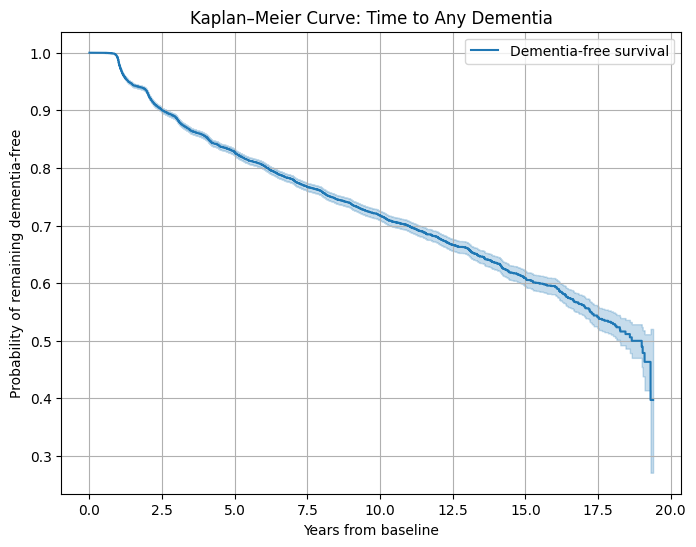

In [13]:
from lifelines import KaplanMeierFitter
import matplotlib.pyplot as plt

kmf = KaplanMeierFitter()

kmf.fit(
    durations=surv_main["time_to_event"],
    event_observed=surv_main["event_any_dementia"],
    label="Dementia-free survival"
)

plt.figure(figsize=(8,6))
kmf.plot_survival_function()
plt.title("Kaplan–Meier Curve: Time to Any Dementia")
plt.xlabel("Years from baseline")
plt.ylabel("Probability of remaining dementia-free")
plt.grid(True)
plt.show()

In [14]:
cox_features = [
    "NACCAGE",     
    "SEX",
    "EDUC",
    "NACCMMSE",     
    "CDRSUM",
    "DIABETES",
    "HYPERTEN",
    "HYPERCHO",
    "CBSTROKE",
    "CVAFIB",
    "DEP2YRS",
    "APNEA"
]

In [15]:

baseline_full = (
    df[df["NACCID"].isin(baseline["NACCID"])]
    .sort_values(["NACCID", "visit_date"])
    .groupby("NACCID", as_index=False)
    .first()
)

print("Baseline rows with predictors:", len(baseline_full))
baseline_full.head()

C:\Users\branjan\AppData\Local\Temp\ipykernel_24320\3673114531.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .first()


Baseline rows with predictors: 38341


,NACCID,NACCADC,PACKET,FORMVER,VISITMO,VISITDAY,VISITYR,NACCVNUM,NACCAVST,NACCNVST,NACCDAYS,NACCFDYS,NACCCORE,NACCREAS,NACCREFR,BIRTHMO,BIRTHYR,SEX,HISPANIC,HISPOR,HISPORX,RACE,RACEX,RACESEC,RACESECX,RACETER,RACETERX,PRIMLANG,PRIMLANX,EDUC,MARISTAT,NACCLIVS,INDEPEND,RESIDENC,HANDED,INBIRMO,INBIRYR,INSEX,NEWINF,INHISP,INHISPOR,INHISPOX,NACCNINR,INRACE,INRACEX,INRASEC,INRASECX,INRATER,INRATERX,INEDUC,INRELTO,INRELTOX,INKNOWN,INLIVWTH,INVISITS,INCALLS,INRELY,NACCFAM,NACCMOM,NACCDAD,NACCAM,NACCAMX,NACCAMS,NACCAMSX,NACCFM,NACCFMX,NACCFMS,NACCFMSX,NACCOM,NACCOMX,NACCOMS,NACCOMSX,NACCFADM,NACCFFTD,ANYMEDS,DRUG1,DRUG2,DRUG3,DRUG4,DRUG5,DRUG6,DRUG7,DRUG8,DRUG9,DRUG10,DRUG11,DRUG12,DRUG13,DRUG14,DRUG15,DRUG16,DRUG17,DRUG18,DRUG19,DRUG20,DRUG21,DRUG22,DRUG23,DRUG24,DRUG25,...,NPFTD,NPFTDTDP,NPALSMND,NPOFTD,NPOFTD1,NPOFTD2,NPOFTD3,NPOFTD4,NPOFTD5,NPFTDNO,NPFTDSPC,NPTDPA,NPTDPB,NPTDPC,NPTDPD,NPTDPE,NPPDXA,NPPDXB,NACCPRIO,NPPDXD,NPPDXE,NPPDXF,NPPDXG,NPPDXH,NPPDXI,NPPDXJ,NPPDXK,NPPDXL,NPPDXM,NPPDXN,NACCDOWN,NPPDXP,NPPDXQ,NACCOTHP,NACCWRI1,NACCWRI2,NACCWRI3,NACCBNKF,NPBNKB,NACCFORM,NACCPARA,NACCCSFP,NPBNKF,NPFAUT,NPFAUT1,NPFAUT2,NPFAUT3,NPFAUT4,NACCDAGE,NACCINT,NPNIT,NPCERAD,NPADRDA,NPOCRIT,NPVOTH,NPLEWYCS,NPGENE,NPFHSPEC,NPTAUHAP,NPPRNP,NPCHROM,NPPNORM,NPCNORM,NPPADP,NPCADP,NPPAD,NPCAD,NPPLEWY,NPCLEWY,NPPVASC,NPCVASC,NPPFTLD,NPCFTLD,NPPHIPP,NPCHIPP,NPPPRION,NPCPRION,NPPOTH1,NPCOTH1,NPOTH1X,NPPOTH2,NPCOTH2,NPOTH2X,NPPOTH3,NPCOTH3,NPOTH3X,NPARTAG,NPATGSEV,NPATGAMY,NPATGAM1,NPATGAM2,NPATGAM3,NPATGAM4,NPATGAM5,NPATGFRN,NPATGFR1,NPATGFR2,NPATGFR3,NPATGFR4,visit_date
0,NACC000011,1416,I,1.0,4,17,2006,1,4,4,1204,0,1,1,8,2,1944,2,0,88,None,1,None,88,None,88,None,1,None,16,1,2,1,1,2,10,1930,1,-4,0,88,None,1,1,None,88,None,88,None,12,5,None,-4,0,2,1,0,9,9,9,-4,None,-4,None,-4,None,-4,None,-4,None,-4,None,0,0,1,CONJUGATED ESTROGENS,CALCIUM-VITAMIN D,CALCIUM-VITAMIN D,MULTIVITAMIN,GLUCOSAMINE,UBIQUINONE,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,...,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,None,None,None,-4,-4,-4,-4,-4,-4,-4,None,None,None,None,888,888,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,None,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,None,-4.0,-4.0,None,-4.0,-4.0,None,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,2006-04-17
1,NACC000034,9661,I,3.0,7,16,2015,1,7,6,2552,0,1,1,1,8,1935,2,0,88,None,1,None,88,None,88,None,1,None,15,2,1,1,1,2,1,1960,2,-4,0,88,None,1,1,None,88,None,88,None,12,2,None,55,0,5,3,0,1,1,1,0,None,-4,None,0,None,-4,None,0,None,-4,None,0,0,1,ATENOLOL,ASPIRIN,LEVOTHYROXINE,OMEGA-3 POLYUNSATURATED FATTY ACIDS,LISINOPRIL,CHOLECALCIFEROL,CALCIUM-VITAMIN D,MULTIVITAMIN,FLAX,MULTIVITAMIN,MULTIVITAMIN WITH MINERALS,ZINC SULFATE,DONEPEZIL,FLAX,UBIQUINONE,BIFIDOBACTERIUM-LACTOBACILLUS,None,None,None,None,None,None,None,None,None,...,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,None,None,None,-4,-4,-4,-4,-4,-4,-4,None,None,None,None,888,888,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,None,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,None,-4.0,-4.0,None,-4.0,-4.0,None,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,2015-07-16
2,NACC000067,2096,I,2.0,5,23,2012,1,3,3,763,0,1,1,2,4,1952,1,0,88,None,1,None,88,None,88,None,1,None,18,1,2,2,1,1,1,1948,2,-4,0,88,None,1,1,None,88,None,88,None,16,1,None,-4,1,8,8,0,1,1,0,-4,None,-4,None,-4,None,-4,None,-4,None,-4,None,0,0,1,LORAZEPAM,CHOLESTYRAMINE,DOXEPIN,CYANOCOBALAMIN,ZOLPIDEM,LOPERAMIDE,ACETAMINOPHEN-HYDROCODONE,CARBIDOPA-LEVODOPA,TIMOLOL OPHTHALMIC,BRIMONIDINE OPHTHALMIC,TESTOSTERONE TOPICAL,CITALOPRAM,BIMATOPROST OPHTHALMIC,BIMATOPROST OPHTHALMIC,MELATONIN,CITALOPRAM,None,None,None,None,None,None,None,None,None,...,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,None,None,None,-4,-4,-4,

In [16]:
baseline_features = baseline_full[["NACCID"] + [c for c in cox_features if c in baseline_full.columns]].copy()

# Merging into survival dataframe
cox_df = surv_main.merge(baseline_features, on="NACCID", how="left")

print("Rows after merge:", len(cox_df))
cox_df.head()

Rows after merge: 27094


,NACCID,baseline_date,max_follow_years,dementia_date,time_to_dem_years,subtype_primary_contrib_any,event_observed,time_to_event,event_type,event_any_dementia,NACCAGE,SEX,EDUC,NACCMMSE,CDRSUM,DIABETES,HYPERTEN,HYPERCHO,CBSTROKE,CVAFIB,DEP2YRS,APNEA
0,NACC000011,2006-04-17,3.296372,NaT,NaN,NaN,0,3.296372,Censored,0,62,2,16,30,0.5,0,0,0,0,0,0,-4
1,NACC000034,2015-07-16,6.986995,2021-05-21,5.848049,AD,1,5.848049,AD,1,79,2,15,-4,0.5,0,1,0,0,0,0,0
2,NACC000067,2012-05-23,2.088980,NaT,NaN,NaN,0,2.088980,Censored,0,60,1,18,29,0.5,0,0,0,0,0,1,-4
3,NACC000138,2023-07-13,1.043121,NaT,NaN,NaN,0,1.043121,Censored,0,54,2,16,-4,0.0,0,0,0,0,0,0,0
4,NACC000144,2010-08-17,8.487337,NaT,NaN,NaN,0,8.487337,Censored,0,79,1,18,30,0.0,0,1,1,0,1,1,-4


In [17]:
cox_df["event_any_dementia"] = (cox_df["event_type"] != "Censored").astype(int)

In [18]:
model_cols = ["time_to_event", "event_any_dementia"] + [c for c in cox_features if c in cox_df.columns]
cox_df_model = cox_df[model_cols].copy()

print(cox_df_model.columns.tolist())

['time_to_event', 'event_any_dementia', 'NACCAGE', 'SEX', 'EDUC', 'NACCMMSE', 'CDRSUM', 'DIABETES', 'HYPERTEN', 'HYPERCHO', 'CBSTROKE', 'CVAFIB', 'DEP2YRS', 'APNEA']


In [19]:
for col in cox_df_model.columns:
    if col in ["time_to_event", "event_any_dementia"]:
        continue
    if cox_df_model[col].dtype.kind in "biufc":
        cox_df_model[col] = cox_df_model[col].fillna(cox_df_model[col].median())
    else:
        mode_vals = cox_df_model[col].mode()
        if len(mode_vals) > 0:
            cox_df_model[col] = cox_df_model[col].fillna(mode_vals.iloc[0])

In [20]:
cox_df_model = cox_df_model[
    cox_df_model["time_to_event"].notna() &
    (cox_df_model["time_to_event"] > 0)
].copy()

print("Final Cox rows:", len(cox_df_model))

Final Cox rows: 27094


In [21]:
from lifelines import CoxPHFitter

cox = CoxPHFitter(penalizer=0.1)
cox.fit(
    cox_df_model,
    duration_col="time_to_event",
    event_col="event_any_dementia"
)

cox.print_summary()

<lifelines.CoxPHFitter: fitted with 27094 total observations, 22201 right-censored observations>
             duration col = 'time_to_event'
                event col = 'event_any_dementia'
                penalizer = 0.1
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 27094
number of events observed = 4893
   partial log-likelihood = -43951.80
         time fit was run = 2026-03-08 01:55:13 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
NACCAGE    0.03      1.03      0.00            0.03            0.04                1.03                1.04
SEX       -0.17      0.85      0.02           -0.21           -0.12                0.81                0.88
EDUC      -0.00      1.00      0.00           -0.01            0.00                0.99                1.00
NACCMMSE  -0.00      1.00      0.00           -0.00           -0.00                1.00                1.00
CDRSUM     0.55      1.74      0.01            0.54            0.57                1.72                1.77
DIABETES  -0.04      0.96      0.02           -0.08           -0.01                0.92                0.99
HYPERTEN  -0.00      1.00      0.01           -0.03            0.03                0.97                1.03
HYPERCHO   0.01      1.01      0.01           -0.01            0.03                0.99                1.03
CBSTROKE   0.03      1.03      0.02           -0.01            0.06                0.99                1.06
CVAFIB     0.01      1.01      0.01           -0.02            0.04                0.98                1.04
DEP2YRS    0.06      1.06      0.01            0.04            0.08                1.04                1.09
APNEA     -0.02      0.98      0.01           -0.03           -0.00                0.97                1.00

           cmp to     z      p  -log2(p)
covariate                               
NACCAGE      0.00 26.93 <0.005    528.12
SEX          0.00 -7.22 <0.005     40.85
EDUC         0.00 -1.08   0.28      1.83
NACCMMSE     0.00 -3.47 <0.005     10.90
CDRSUM       0.00 74.84 <0.005       inf
DIABETES     0.00 -2.44   0.01      6.08
HYPERTEN     0.00 -0.18   0.86      0.23
HYPERCHO     0.00  0.73   0.46      1.11
CBSTROKE     0.00  1.52   0.13      2.97
CVAFIB       0.00  0.49   0.62      0.68
DEP2YRS      0.00  5.07 <0.005     21.27
APNEA        0.00 -2.65   0.01      6.98
---
Concordance = 0.85
Partial AIC = 87927.60
log-likelihood ratio test = 4399.23 on 12 df
-log2(p) of ll-ratio test = inf

In [22]:
hr_table = cox.summary[[
    "coef",
    "exp(coef)",
    "se(coef)",
    "p"
]].copy()

hr_table = hr_table.rename(columns={
    "coef": "log_hazard",
    "exp(coef)": "hazard_ratio",
    "se(coef)": "se",
    "p": "p_value"
})

hr_table.sort_values("p_value").head(20)

,log_hazard,hazard_ratio,se,p_value
covariate,,,,
CDRSUM,0.554853,1.741684,0.007414,0.000000e+00
NACCAGE,0.033515,1.034083,0.001245,1.047838e-159
SEX,-0.168039,0.845321,0.023261,5.050540e-13
DEP2YRS,0.059820,1.061645,0.011796,3.952544e-07
NACCMMSE,-0.002563,0.997441,0.000739,5.231095e-04
APNEA,-0.015181,0.984934,0.005718,7.935185e-03
DIABETES,-0.044647,0.956335,0.018321,1.480994e-02
CBSTROKE,0.027426,1.027805,0.018014,1.278872e-01
EDUC,-0.002151,0.997852,0.001993,2.805214e-01


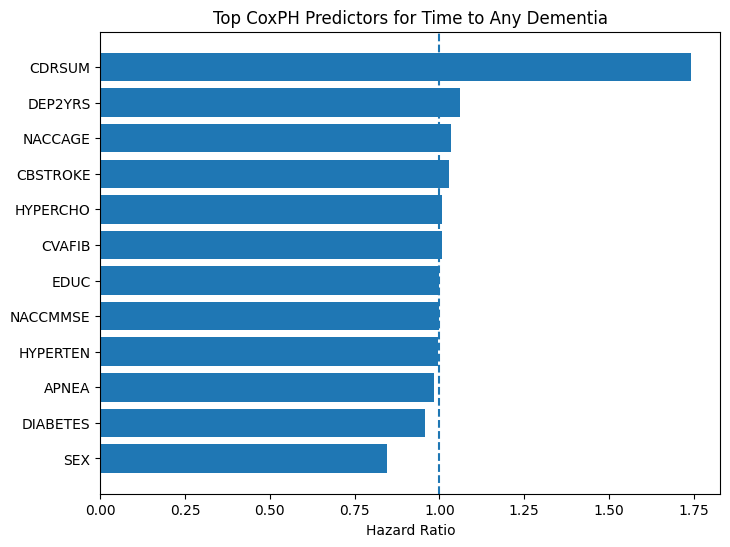

In [23]:
import matplotlib.pyplot as plt

top_hr = hr_table.sort_values("p_value").head(12).sort_values("hazard_ratio")

plt.figure(figsize=(8,6))
plt.barh(top_hr.index.astype(str), top_hr["hazard_ratio"])
plt.axvline(1.0, linestyle="--")
plt.xlabel("Hazard Ratio")
plt.title("Top CoxPH Predictors for Time to Any Dementia")
plt.show()

In [24]:
cox.check_assumptions(cox_df_model, p_value_threshold=0.05, show_plots=False)

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'NACCAGE' failed the non-proportional test: p-value is <5e-05.

   Advice 1: the functional form of the variable 'NACCAGE' might be incorrect. That is, there may be
non-linear terms missing. The proportional hazard test used is very sensitive to incorrect
functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'NACCAGE' using pd.cut, and then specify it in
`strata=['NACCAGE', ...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


2. Variable 'SEX' failed the non-proportional test: p-value is 0.0173.

   Advice: with so few unique values (only 2), you can include `strata=['SEX', ...]` in the call in
`.fit`. See documentation in link [E] below.

3. Variable 'CDRSUM' failed the non-proportional test: p-value is <5e-05.

   Advice 1: the functional form of the variable 'CDRSUM' might b

[]

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lifelines import CoxPHFitter, KaplanMeierFitter, AalenJohansenFitter
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [26]:
# =========================================================
# MASTER MODELING DATAFRAME
# =========================================================

# Start from cox_df (already merged with baseline features)
model_df = cox_df.copy()

# Binary event
model_df["event_any_dementia"] = (model_df["event_type"] != "Censored").astype(int)

# Keep only rows with valid time
model_df = model_df[
    model_df["time_to_event"].notna() &
    (model_df["time_to_event"] > 0)
].copy()

print("model_df shape:", model_df.shape)
print(model_df["event_type"].value_counts(dropna=False))

model_df shape: (27094, 22)
event_type
Censored    22201
AD           4481
PD_LBD        326
Vascular       86
Name: count, dtype: int64


1) COMPETING RISKS
Cell 26 — Numeric code for competing events

In [27]:
# =========================================================
# COMPETING RISK EVENT CODING
# 0 = censored
# 1 = AD
# 2 = PD_LBD
# 3 = Vascular
# =========================================================

event_code_map = {
    "Censored": 0,
    "AD": 1,
    "PD_LBD": 2,
    "Vascular": 3
}

cr_df = model_df[model_df["event_type"].isin(event_code_map.keys())].copy()
cr_df["event_code"] = cr_df["event_type"].map(event_code_map).astype(int)

print(cr_df["event_type"].value_counts())
print(cr_df["event_code"].value_counts())

event_type
Censored    22201
AD           4481
PD_LBD        326
Vascular       86
Name: count, dtype: int64
event_code
0    22201
1     4481
2      326
3       86
Name: count, dtype: int64


Cell 27 — Cumulative incidence curves (Aalen-Johansen)

This is a very nice plot for your poster/results.

c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(


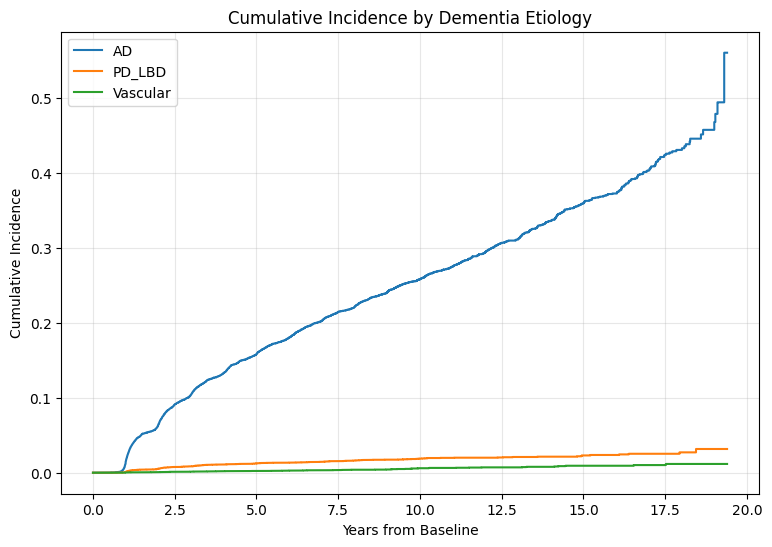

In [28]:
# =========================================================
# CUMULATIVE INCIDENCE CURVES FOR COMPETING RISKS
# =========================================================

plt.figure(figsize=(9, 6))

for event_name, event_code in [("AD", 1), ("PD_LBD", 2), ("Vascular", 3)]:
    ajf = AalenJohansenFitter()
    ajf.fit(
        durations=cr_df["time_to_event"],
        event_observed=cr_df["event_code"],
        event_of_interest=event_code
    )
    ajf.plot(ci_show=False)

plt.title("Cumulative Incidence by Dementia Etiology")
plt.xlabel("Years from Baseline")
plt.ylabel("Cumulative Incidence")
plt.grid(True, alpha=0.3)
plt.legend(["AD", "PD_LBD", "Vascular"])
plt.show()

2) CAUSE-SPECIFIC COX MODELS
Cell 28 — Helper to fit cause-specific Cox

In [29]:
# =========================================================
# CAUSE-SPECIFIC COX HELPER
# =========================================================

def fit_cause_specific_cox(df, event_name, features, penalizer=0.1):
    tmp = df.copy()
    tmp["event_cs"] = (tmp["event_type"] == event_name).astype(int)

    use_cols = ["time_to_event", "event_cs"] + [c for c in features if c in tmp.columns]
    tmp = tmp[use_cols].copy()

    # simple imputation
    for col in tmp.columns:
        if col in ["time_to_event", "event_cs"]:
            continue
        if pd.api.types.is_numeric_dtype(tmp[col]):
            tmp[col] = tmp[col].fillna(tmp[col].median())
        else:
            mode_vals = tmp[col].mode()
            if len(mode_vals) > 0:
                tmp[col] = tmp[col].fillna(mode_vals.iloc[0])

    # one-hot encode categorical if present
    cat_cols = [c for c in tmp.columns if c not in ["time_to_event", "event_cs"] and not pd.api.types.is_numeric_dtype(tmp[c])]
    if len(cat_cols) > 0:
        tmp = pd.get_dummies(tmp, columns=cat_cols, drop_first=True)

    cph = CoxPHFitter(penalizer=penalizer)
    cph.fit(tmp, duration_col="time_to_event", event_col="event_cs")
    return cph, tmp

Cell 29 — Run cause-specific Cox for AD / PD_LBD / Vascular

In [30]:
# =========================================================
# CAUSE-SPECIFIC COX MODELS
# =========================================================

cause_features = [
    "NACCAGE",
    "SEX",
    "EDUC",
    "NACCMMSE",
    "CDRSUM",
    "DIABETES",
    "HYPERTEN",
    "HYPERCHO",
    "CBSTROKE",
    "CVAFIB",
    "DEP2YRS"
]

cause_models = {}
cause_dfs = {}

for outcome in ["AD", "PD_LBD", "Vascular"]:
    cph, tmp_df = fit_cause_specific_cox(model_df, outcome, cause_features, penalizer=0.1)
    cause_models[outcome] = cph
    cause_dfs[outcome] = tmp_df

    print("\n" + "=" * 70)
    print(f"CAUSE-SPECIFIC COX FOR: {outcome}")
    print("=" * 70)
    display(
        cph.summary[["coef", "exp(coef)", "se(coef)", "p"]]
        .sort_values("p")
        .head(15)
    )


CAUSE-SPECIFIC COX FOR: AD


,coef,exp(coef),se(coef),p
covariate,,,,
CDRSUM,0.545790,1.725971,0.007839,0.000000e+00
NACCAGE,0.034308,1.034903,0.001277,4.380480e-159
SEX,-0.108239,0.897413,0.023967,6.294531e-06
DEP2YRS,0.052450,1.053849,0.012276,1.932870e-05
DIABETES,-0.033674,0.966887,0.018455,6.805387e-02
EDUC,-0.003253,0.996752,0.002075,1.168457e-01
NACCMMSE,-0.000965,0.999036,0.000677,1.540465e-01
CBSTROKE,0.018915,1.019095,0.018969,3.187020e-01
HYPERCHO,0.004947,1.004959,0.011445,6.655971e-01



CAUSE-SPECIFIC COX FOR: PD_LBD


,coef,exp(coef),se(coef),p
covariate,,,,
CDRSUM,0.157013,1.170010,0.019082,1.896532e-16
SEX,-0.178566,0.836469,0.036984,1.377885e-06
DEP2YRS,0.028376,1.028783,0.019824,1.523165e-01
CVAFIB,0.026033,1.026375,0.022976,2.571841e-01
NACCMMSE,-0.000961,0.999039,0.000993,3.327958e-01
DIABETES,-0.022846,0.977413,0.027256,4.019187e-01
NACCAGE,0.001050,1.001051,0.001826,5.651305e-01
EDUC,0.001632,1.001633,0.002897,5.731648e-01
HYPERTEN,-0.010990,0.989070,0.022995,6.327057e-01



CAUSE-SPECIFIC COX FOR: Vascular


,coef,exp(coef),se(coef),p
covariate,,,,
CDRSUM,0.034606,1.035212,0.019925,0.082414
CBSTROKE,0.043279,1.044229,0.032897,0.188320
NACCAGE,0.001658,1.001659,0.001900,0.382778
HYPERCHO,0.013935,1.014033,0.018032,0.439623
NACCMMSE,-0.000734,0.999266,0.001033,0.477044
HYPERTEN,0.010770,1.010828,0.023875,0.651921
SEX,-0.016232,0.983899,0.038590,0.674026
DIABETES,0.005328,1.005342,0.028165,0.849960
EDUC,-0.000385,0.999615,0.003026,0.898679


Cell 30 — Plot top hazard ratios for each cause-specific model

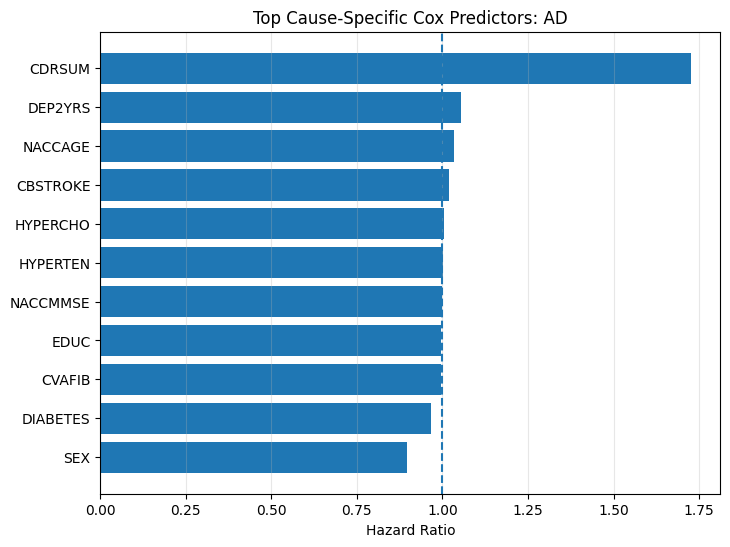

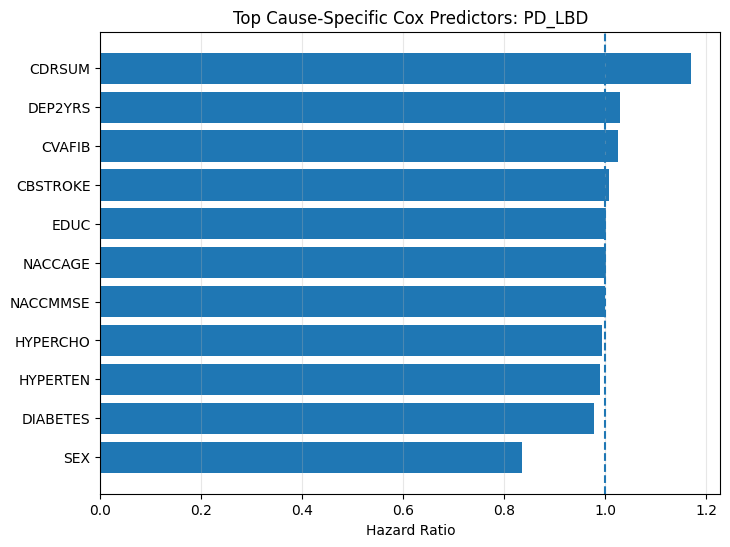

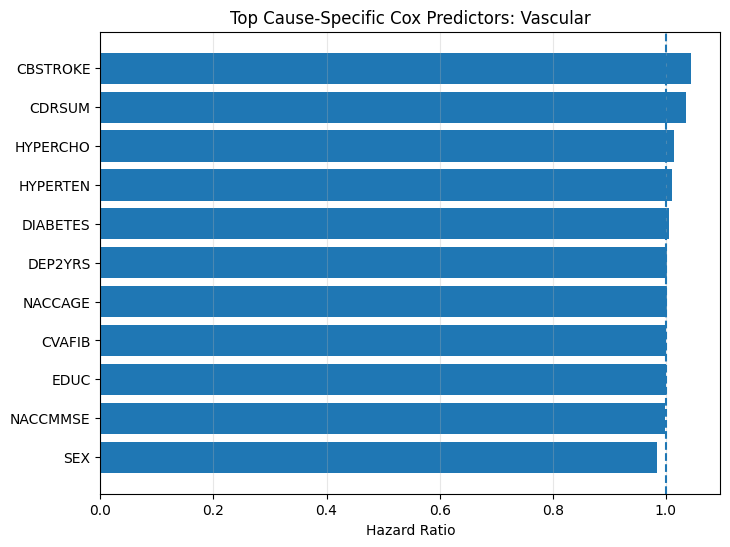

In [31]:
# =========================================================
# TOP HR PLOTS FOR EACH ETIOLOGY
# =========================================================

for outcome, cph in cause_models.items():
    hr_table = cph.summary[["exp(coef)", "p"]].copy()
    hr_table = hr_table.rename(columns={"exp(coef)": "hazard_ratio", "p": "p_value"})
    hr_table = hr_table.sort_values("p_value").head(12).sort_values("hazard_ratio")

    plt.figure(figsize=(8, 6))
    plt.barh(hr_table.index.astype(str), hr_table["hazard_ratio"])
    plt.axvline(1.0, linestyle="--")
    plt.xlabel("Hazard Ratio")
    plt.title(f"Top Cause-Specific Cox Predictors: {outcome}")
    plt.grid(True, axis="x", alpha=0.3)
    plt.show()

3) VASCULAR BURDEN INDEX

This is one of the best additions for your notebook.

Cell 31 — Build vascular burden index

In [32]:
# =========================================================
# VASCULAR BURDEN INDEX
# =========================================================

vascular_candidates = [
    "CBSTROKE",   # stroke
    "HYPERTEN",   # HTN
    "DIABETES",   # diabetes
    "HYPERCHO",   # hypercholesterolemia
    "CVAFIB",     # afib
    "CVCHF",      # CHF if present
    "CBTIA",      # TIA if present
    "BPSYS",      # systolic BP if present
    "BPDIAS",     # diastolic BP if present
    "SMOKYRS",    # smoking years if present
    "PACKSPER"    # smoking intensity if present
]

vascular_features = [c for c in vascular_candidates if c in model_df.columns]
print("vascular_features:", vascular_features)

# Define target: vascular dementia vs everyone else
vbi_df = model_df.copy()
vbi_df["vascular_target"] = (vbi_df["event_type"] == "Vascular").astype(int)

X_vbi = vbi_df[vascular_features].copy()
y_vbi = vbi_df["vascular_target"].copy()

# Fill missing
for col in X_vbi.columns:
    if pd.api.types.is_numeric_dtype(X_vbi[col]):
        X_vbi[col] = X_vbi[col].fillna(X_vbi[col].median())
    else:
        mode_vals = X_vbi[col].mode()
        if len(mode_vals) > 0:
            X_vbi[col] = X_vbi[col].fillna(mode_vals.iloc[0])

# One-hot if needed
cat_cols = [c for c in X_vbi.columns if not pd.api.types.is_numeric_dtype(X_vbi[c])]
if len(cat_cols) > 0:
    X_vbi = pd.get_dummies(X_vbi, columns=cat_cols, drop_first=True)

vbi_model = LogisticRegression(
    class_weight="balanced",
    max_iter=5000,
    random_state=RANDOM_STATE
)
vbi_model.fit(X_vbi, y_vbi)

# Probability = vascular burden index
vbi_df["vascular_burden_index"] = vbi_model.predict_proba(X_vbi)[:, 1]

print(vbi_df["vascular_burden_index"].describe())

vascular_features: ['CBSTROKE', 'HYPERTEN', 'DIABETES', 'HYPERCHO', 'CVAFIB']
count    27094.000000
mean         0.452375
std          0.110958
min          0.002693
25%          0.348148
50%          0.461864
75%          0.522151
max          0.999987
Name: vascular_burden_index, dtype: float64


Cell 32 — Inspect vascular burden weights

In [33]:
# =========================================================
# INSPECT VASCULAR BURDEN MODEL WEIGHTS
# =========================================================

vbi_coef = pd.DataFrame({
    "feature": X_vbi.columns,
    "coef": vbi_model.coef_[0]
}).sort_values("coef", ascending=False)

display(vbi_coef)

,feature,coef
0,CBSTROKE,0.683869
1,HYPERTEN,0.474351
3,HYPERCHO,0.241502
2,DIABETES,0.009893
4,CVAFIB,-0.087811


Cell 33 — Merge vascular burden into survival modeling

In [34]:
# =========================================================
# ADD VBI INTO SURVIVAL MODEL
# =========================================================

model_df = model_df.merge(
    vbi_df[["NACCID", "vascular_burden_index"]],
    on="NACCID",
    how="left"
)

# If duplicate merge created repeated columns, fix safely
if "vascular_burden_index_x" in model_df.columns:
    model_df["vascular_burden_index"] = model_df["vascular_burden_index_x"]
    drop_cols = [c for c in ["vascular_burden_index_x", "vascular_burden_index_y"] if c in model_df.columns]
    model_df = model_df.drop(columns=drop_cols)

print(model_df[["NACCID", "vascular_burden_index"]].head())

       NACCID  vascular_burden_index
0  NACC000011               0.348148
1  NACC000034               0.461864
2  NACC000067               0.348148
3  NACC000138               0.348148
4  NACC000144               0.500213


Cell 34 — Refit any-dementia Cox with vascular burden index

In [35]:
# =========================================================
# ANY-DEMENTIA COX + VASCULAR BURDEN INDEX
# =========================================================

cox_features_plus_vbi = [
    "NACCAGE",
    "SEX",
    "EDUC",
    "NACCMMSE",
    "CDRSUM",
    "DIABETES",
    "HYPERTEN",
    "HYPERCHO",
    "CBSTROKE",
    "CVAFIB",
    "DEP2YRS",
    "vascular_burden_index"
]

cox_vbi_df = model_df[["time_to_event", "event_any_dementia"] + [c for c in cox_features_plus_vbi if c in model_df.columns]].copy()

for col in cox_vbi_df.columns:
    if col in ["time_to_event", "event_any_dementia"]:
        continue
    if pd.api.types.is_numeric_dtype(cox_vbi_df[col]):
        cox_vbi_df[col] = cox_vbi_df[col].fillna(cox_vbi_df[col].median())
    else:
        mode_vals = cox_vbi_df[col].mode()
        if len(mode_vals) > 0:
            cox_vbi_df[col] = cox_vbi_df[col].fillna(mode_vals.iloc[0])

cat_cols = [c for c in cox_vbi_df.columns if c not in ["time_to_event", "event_any_dementia"] and not pd.api.types.is_numeric_dtype(cox_vbi_df[c])]
if len(cat_cols) > 0:
    cox_vbi_df = pd.get_dummies(cox_vbi_df, columns=cat_cols, drop_first=True)

cox_vbi = CoxPHFitter(penalizer=0.1)
cox_vbi.fit(cox_vbi_df, duration_col="time_to_event", event_col="event_any_dementia")

display(
    cox_vbi.summary[["coef", "exp(coef)", "se(coef)", "p"]]
    .sort_values("p")
    .head(20)
)

,coef,exp(coef),se(coef),p
covariate,,,,
CDRSUM,0.555768,1.743280,0.007419,0.000000e+00
NACCAGE,0.033585,1.034155,0.001246,5.068021e-160
SEX,-0.167572,0.845716,0.023264,5.883503e-13
DEP2YRS,0.057938,1.059649,0.011736,7.948136e-07
NACCMMSE,-0.001718,0.998283,0.000662,9.429207e-03
DIABETES,-0.046879,0.954203,0.018271,1.029569e-02
EDUC,-0.002273,0.997730,0.001996,2.548137e-01
CBSTROKE,0.021158,1.021383,0.019531,2.786880e-01
vascular_burden_index,0.109287,1.115482,0.128895,3.965079e-01


Cell 35 — Survival curves stratified by vascular burden tertiles

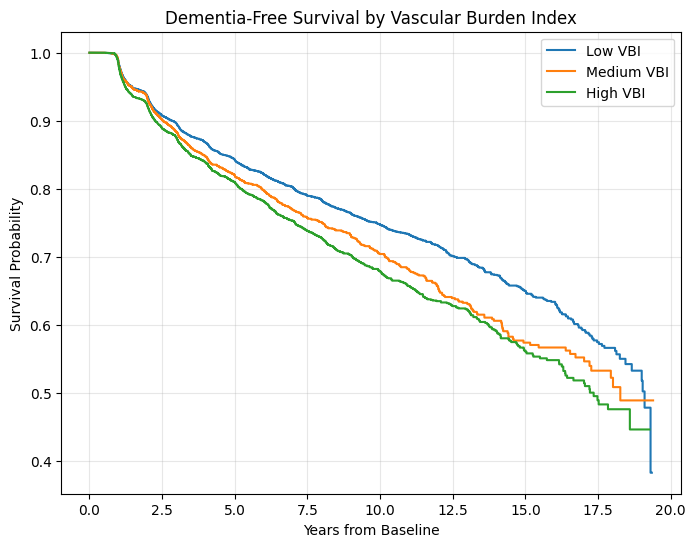

In [36]:
# =========================================================
# KAPLAN-MEIER BY VASCULAR BURDEN TERTILE
# =========================================================

km_vbi_df = model_df[["time_to_event", "event_any_dementia", "vascular_burden_index"]].dropna().copy()
km_vbi_df["vbi_group"] = pd.qcut(
    km_vbi_df["vascular_burden_index"],
    q=3,
    labels=["Low VBI", "Medium VBI", "High VBI"]
)

plt.figure(figsize=(8, 6))
kmf = KaplanMeierFitter()

for grp in ["Low VBI", "Medium VBI", "High VBI"]:
    tmp = km_vbi_df[km_vbi_df["vbi_group"] == grp]
    kmf.fit(
        durations=tmp["time_to_event"],
        event_observed=tmp["event_any_dementia"],
        label=grp
    )
    kmf.plot(ci_show=False)

plt.title("Dementia-Free Survival by Vascular Burden Index")
plt.xlabel("Years from Baseline")
plt.ylabel("Survival Probability")
plt.grid(True, alpha=0.3)
plt.show()

4) BOOTSTRAP UNCERTAINTY-AWARE SURVIVAL PREDICTION
Cell 36 — Bootstrap Cox ensemble

This estimates prediction uncertainty.

In [38]:
# =========================================================
# BOOTSTRAP ENSEMBLE FOR UNCERTAINTY  --- FIXED
# =========================================================

N_BOOT = 30
PRED_HORIZON_YEARS = 5.0

boot_features = [
    "NACCAGE",
    "SEX",
    "EDUC",
    "NACCMMSE",
    "CDRSUM",
    "DIABETES",
    "HYPERTEN",
    "HYPERCHO",
    "CBSTROKE",
    "CVAFIB",
    "DEP2YRS",
    "vascular_burden_index"
]

# Keep NACCID only for tracking, not for model fitting
boot_df = model_df[["NACCID", "time_to_event", "event_any_dementia"] + [c for c in boot_features if c in model_df.columns]].copy()

# Fill missing values
for col in boot_df.columns:
    if col in ["NACCID", "time_to_event", "event_any_dementia"]:
        continue
    if pd.api.types.is_numeric_dtype(boot_df[col]):
        boot_df[col] = boot_df[col].fillna(boot_df[col].median())
    else:
        mode_vals = boot_df[col].mode()
        if len(mode_vals) > 0:
            boot_df[col] = boot_df[col].fillna(mode_vals.iloc[0])

# One-hot encode categorical columns
cat_cols = [
    c for c in boot_df.columns
    if c not in ["NACCID", "time_to_event", "event_any_dementia"]
    and not pd.api.types.is_numeric_dtype(boot_df[c])
]
if len(cat_cols) > 0:
    boot_df = pd.get_dummies(boot_df, columns=cat_cols, drop_first=True)

# Columns actually used in Cox model
fit_cols = [c for c in boot_df.columns if c != "NACCID"]

# Predictor columns only
boot_feature_cols = [
    c for c in fit_cols
    if c not in ["time_to_event", "event_any_dementia"]
]

risk_preds = []

for b in range(N_BOOT):
    sample_idx = np.random.choice(len(boot_df), size=len(boot_df), replace=True)

    # sample rows, but only pass numeric fit columns to Cox
    boot_sample = boot_df.iloc[sample_idx][fit_cols].copy()

    cph_b = CoxPHFitter(penalizer=0.1)
    cph_b.fit(
        boot_sample,
        duration_col="time_to_event",
        event_col="event_any_dementia"
    )

    surv_funcs = cph_b.predict_survival_function(
        boot_df[boot_feature_cols],
        times=[PRED_HORIZON_YEARS]
    )

    risk_5y = 1.0 - surv_funcs.T.iloc[:, 0].values
    risk_preds.append(risk_5y)

risk_preds = np.vstack(risk_preds)

print("risk_preds shape:", risk_preds.shape)
print("n patients:", len(boot_df))
print("n feature cols:", len(boot_feature_cols))

risk_preds shape: (30, 27094)
n patients: 27094
n feature cols: 12


Cell 37 — Compute uncertainty + confidence

In [39]:
# =========================================================
# UNCERTAINTY / CONFIDENCE SCORES
# =========================================================

uncertainty_df = boot_df[["NACCID", "time_to_event", "event_any_dementia"]].copy()
uncertainty_df["risk_5y_mean"] = risk_preds.mean(axis=0)
uncertainty_df["risk_5y_std"]  = risk_preds.std(axis=0)
uncertainty_df["risk_5y_p10"]  = np.percentile(risk_preds, 10, axis=0)
uncertainty_df["risk_5y_p90"]  = np.percentile(risk_preds, 90, axis=0)

# simple confidence score
max_std = uncertainty_df["risk_5y_std"].max()
uncertainty_df["confidence_score"] = 1 - (uncertainty_df["risk_5y_std"] / max_std)
uncertainty_df["confidence_score"] = uncertainty_df["confidence_score"].clip(0, 1)

display(uncertainty_df.head())
display(uncertainty_df.describe())

,NACCID,time_to_event,event_any_dementia,risk_5y_mean,risk_5y_std,risk_5y_p10,risk_5y_p90,confidence_score
0,NACC000011,3.296372,0,0.101402,0.002455,0.097520,0.104599,0.968297
1,NACC000034,5.848049,1,0.183125,0.003890,0.178906,0.187145,0.949763
2,NACC000067,2.088980,0,0.116115,0.003106,0.112106,0.119177,0.959892
3,NACC000138,1.043121,0,0.063089,0.001870,0.060599,0.064967,0.975853
4,NACC000144,8.487337,0,0.164388,0.005216,0.158366,0.170725,0.932641


,time_to_event,event_any_dementia,risk_5y_mean,risk_5y_std,risk_5y_p10,risk_5y_p90,confidence_score
count,27094.000000,27094.000000,27094.000000,27094.000000,27094.000000,27094.000000,27094.000000
mean,5.118849,0.180593,0.179270,0.006021,0.172215,0.187061,0.922234
std,4.217142,0.384688,0.136589,0.006488,0.130693,0.144003,0.083788
min,0.109514,0.000000,0.019435,0.000000,0.017988,0.021259,0.000000
25%,1.938398,0.000000,0.102011,0.002598,0.098507,0.105640,0.922853
50%,3.782341,0.000000,0.135657,0.003605,0.130988,0.140567,0.953443
75%,7.126626,0.000000,0.197619,0.005974,0.190179,0.205204,0.966447
max,19.392197,1.000000,1.000000,0.077431,1.000000,1.000000,1.000000


Cell 38 — Scatter plot: risk vs uncertainty

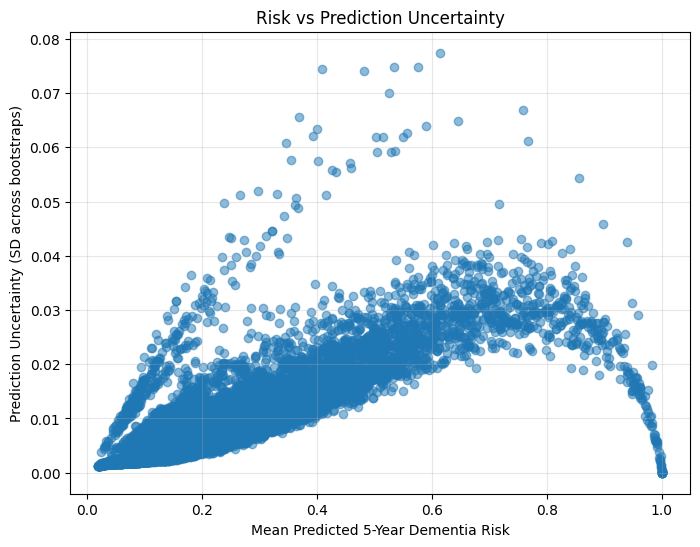

In [40]:
# =========================================================
# RISK VS UNCERTAINTY PLOT
# =========================================================

plt.figure(figsize=(8, 6))
plt.scatter(
    uncertainty_df["risk_5y_mean"],
    uncertainty_df["risk_5y_std"],
    alpha=0.5
)
plt.xlabel("Mean Predicted 5-Year Dementia Risk")
plt.ylabel("Prediction Uncertainty (SD across bootstraps)")
plt.title("Risk vs Prediction Uncertainty")
plt.grid(True, alpha=0.3)
plt.show()

Cell 39 — Identify high-uncertainty cases

In [41]:
# =========================================================
# FLAG HIGH-UNCERTAINTY CASES
# =========================================================

uncert_thresh = uncertainty_df["risk_5y_std"].quantile(0.80)
uncertainty_df["high_uncertainty"] = (uncertainty_df["risk_5y_std"] >= uncert_thresh).astype(int)

print("High-uncertainty threshold:", uncert_thresh)
print(uncertainty_df["high_uncertainty"].value_counts())

display(
    uncertainty_df.sort_values("risk_5y_std", ascending=False).head(15)
)

High-uncertainty threshold: 0.007247586011389323
high_uncertainty
0    21675
1     5419
Name: count, dtype: int64


,NACCID,time_to_event,event_any_dementia,risk_5y_mean,risk_5y_std,risk_5y_p10,risk_5y_p90,confidence_score,high_uncertainty
17658,NACC651025,0.996578,1,0.613649,0.077431,0.515502,0.692987,0.000000,1
19949,NACC733402,4.120465,0,0.576201,0.074867,0.480688,0.672811,0.033118,1
11556,NACC427914,9.059548,0,0.534792,0.074840,0.440978,0.630735,0.033454,1
1437,NACC053106,3.099247,0,0.409391,0.074496,0.311870,0.527763,0.037904,1
21273,NACC783316,13.037645,0,0.481265,0.074130,0.399390,0.559999,0.042628,1
18839,NACC693324,2.223135,1,0.525510,0.070000,0.448067,0.584848,0.095967,1
16071,NACC592291,0.982888,0,0.758291,0.066959,0.683540,0.834210,0.135239,1
6418,NACC240534,1.023956,0,0.368750,0.065649,0.304171,0.449493,0.152163,1
22522,NACC828932,1.070500,0,0.646144,0.064784,0.576735,0.730687,0.163333,1
3305,NACC123237,1.190965,0,0.590410,0.063844,0.516893,0.666839,0.175470,1


5) UNCERTAIN-CASE PHENOTYPE ANALYSIS
Cell 40 — Merge uncertainty back to clinical variables

In [42]:
# =========================================================
# MERGE UNCERTAINTY BACK FOR PHENOTYPE ANALYSIS
# =========================================================

analysis_df = model_df.merge(
    uncertainty_df[["NACCID", "risk_5y_mean", "risk_5y_std", "confidence_score", "high_uncertainty"]],
    on="NACCID",
    how="left"
)

print(analysis_df.shape)

(27094, 27)


Cell 41 — Compare high- vs low-uncertainty groups

In [43]:
# =========================================================
# PHENOTYPE COMPARISON: HIGH VS LOW UNCERTAINTY
# =========================================================

compare_vars = [
    "NACCAGE",
    "EDUC",
    "NACCMMSE",
    "CDRSUM",
    "DIABETES",
    "HYPERTEN",
    "HYPERCHO",
    "CBSTROKE",
    "CVAFIB",
    "DEP2YRS",
    "vascular_burden_index"
]

rows = []
for col in compare_vars:
    if col not in analysis_df.columns:
        continue

    tmp0 = analysis_df.loc[analysis_df["high_uncertainty"] == 0, col]
    tmp1 = analysis_df.loc[analysis_df["high_uncertainty"] == 1, col]

    rows.append({
        "variable": col,
        "low_uncert_mean": pd.to_numeric(tmp0, errors="coerce").mean(),
        "high_uncert_mean": pd.to_numeric(tmp1, errors="coerce").mean(),
        "difference": pd.to_numeric(tmp1, errors="coerce").mean() - pd.to_numeric(tmp0, errors="coerce").mean()
    })

uncert_compare = pd.DataFrame(rows).sort_values("difference", ascending=False)
display(uncert_compare)

,variable,low_uncert_mean,high_uncert_mean,difference
0,NACCAGE,69.817901,74.873777,5.055877
3,CDRSUM,0.226182,1.865104,1.638922
1,EDUC,15.898408,16.932460,1.034052
9,DEP2YRS,0.198708,0.698468,0.499760
6,HYPERCHO,0.548143,1.003137,0.454994
7,CBSTROKE,0.013564,0.346374,0.332810
8,CVAFIB,0.073126,0.389924,0.316799
5,HYPERTEN,0.496840,0.783355,0.286515
4,DIABETES,0.130842,0.357815,0.226973
10,vascular_burden_index,0.437390,0.512309,0.074919


Cell 42 — Event-type breakdown inside high-uncertainty cases

In [44]:
# =========================================================
# WHAT TYPES OF EVENTS APPEAR IN HIGH-UNCERTAINTY CASES?
# =========================================================

event_uncert_table = pd.crosstab(
    analysis_df["event_type"],
    analysis_df["high_uncertainty"],
    normalize="columns"
)

display(event_uncert_table)

high_uncertainty,0,1
event_type,,
AD,0.106251,0.401919
Censored,0.885029,0.556929
PD_LBD,0.006644,0.033586
Vascular,0.002076,0.007566


6) OPTIONAL DISAGREEMENT ANALYSIS HOOK

This one needs classifier predictions from your classification notebook.

Expected columns:

NACCID

predicted_class

with values like:

AD

PD_LBD

Vascular

NoDementia_Hy or similar

Cell 43 — Optional disagreement analysis

In [45]:
# =========================================================
# OPTIONAL: DISAGREEMENT ANALYSIS
# Requires a dataframe named clf_preds with:
#   NACCID, predicted_class
# =========================================================

# Example:
# clf_preds = pd.read_csv("../output/classifier_predictions.csv")

if "clf_preds" in globals():
    dis_df = analysis_df.copy()

    # survival-side etiology guess = highest cause-specific cumulative incidence not implemented patient-wise here,
    # so for now use observed event_type as placeholder OR replace later with predicted etiology from your classifier notebook
    dis_df = dis_df.merge(clf_preds[["NACCID", "predicted_class"]], on="NACCID", how="left")

    # normalize classifier label naming if needed
    dis_df["predicted_class_norm"] = dis_df["predicted_class"].replace({
        "NoDementia_Hy": "Censored",
        "NoDementia_5y": "Censored"
    })

    dis_df["model_disagreement"] = (
        dis_df["predicted_class_norm"].notna() &
        (dis_df["predicted_class_norm"] != dis_df["event_type"])
    ).astype(int)

    print(dis_df["model_disagreement"].value_counts(dropna=False))

    display(
        pd.crosstab(dis_df["event_type"], dis_df["model_disagreement"], normalize="columns")
    )

    display(
        dis_df.loc[dis_df["model_disagreement"] == 1,
                   ["NACCID", "event_type", "predicted_class", "risk_5y_mean", "risk_5y_std", "confidence_score"]]
        .head(20)
    )
else:
    print("clf_preds not found. Skipping disagreement analysis.")

clf_preds not found. Skipping disagreement analysis.
